In [ ]:
import pandas as pd

df = pd.read_excel('/returns_dataset.xlsx', sheet_name='Returns_Data')
df['Support_Channel'] = df['Support_Channel'].fillna('No Support Contacted')

print(f"✅ Excel file loaded: {df.shape[0]} rows, {df.shape[1]} columns")
display(df.head())

✅ Excel file loaded: 5000 rows, 16 columns


,Order_ID,Purchase_Date,Return_Request_Date,Days_Since_Purchase,Product_Category,Brand,Product_Price_INR,Return_Reason,Is_Avoidable_Return,Customer_Contacted_Support,Support_Channel,Support_Interaction_Time_Min,Resolution_Type,Return_Prevented,CSAT_Score,Region
0,ORD-000001,2026-01-11,2026-01-18,7,Headphones,Apple,18535,Damaged in Transit,0,0,No Support Contacted,0,Full Refund,0,1,North America
1,ORD-000002,2026-09-14,2026-09-18,4,Smartphones,Samsung,42640,Setup/Configuration Issues,1,0,No Support Contacted,0,Store Credit,0,2,Rest of World
2,ORD-000003,2026-06-28,2026-07-06,8,Laptops,HP,105997,Performance Issues,0,0,No Support Contacted,0,Full Refund,0,3,India
3,ORD-000004,2026-01-15,2026-01-28,13,Speakers,Sony,14366,Compatibility Issues,0,1,Live Chat,6,Repair,0,3,Rest of World
4,ORD-000005,2025-12-11,2026-01-13,33,Tablets,Microsoft,44895,Missing Accessories,1,0,No Support Contacted,0,Store Credit,0,4,India


✅ Dataset loaded: 5000 rows, 16 columns

--- Data Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 16 columns):
 #   Column                        Non-Null Count  Dtype 
---  ------                        --------------  ----- 
 0   Order_ID                      5000 non-null   object
 1   Purchase_Date                 5000 non-null   object
 2   Return_Request_Date           5000 non-null   object
 3   Days_Since_Purchase           5000 non-null   int64 
 4   Product_Category              5000 non-null   object
 5   Brand                         5000 non-null   object
 6   Product_Price_INR             5000 non-null   int64 
 7   Return_Reason                 5000 non-null   object
 8   Is_Avoidable_Return           5000 non-null   int64 
 9   Customer_Contacted_Support    5000 non-null   int64 
 10  Support_Channel               5000 non-null   object
 11  Support_Interaction_Time_Min  5000 non-null   int64 
 12  Resolution_Type  

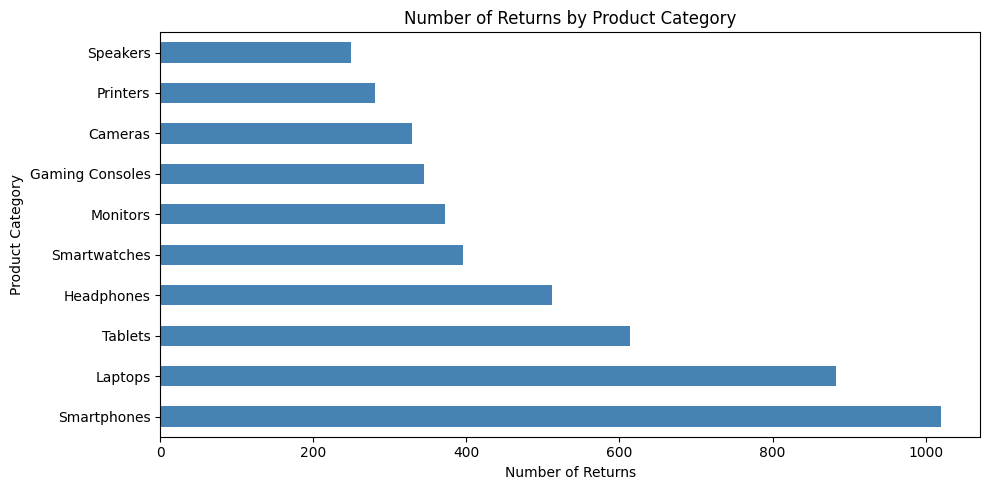

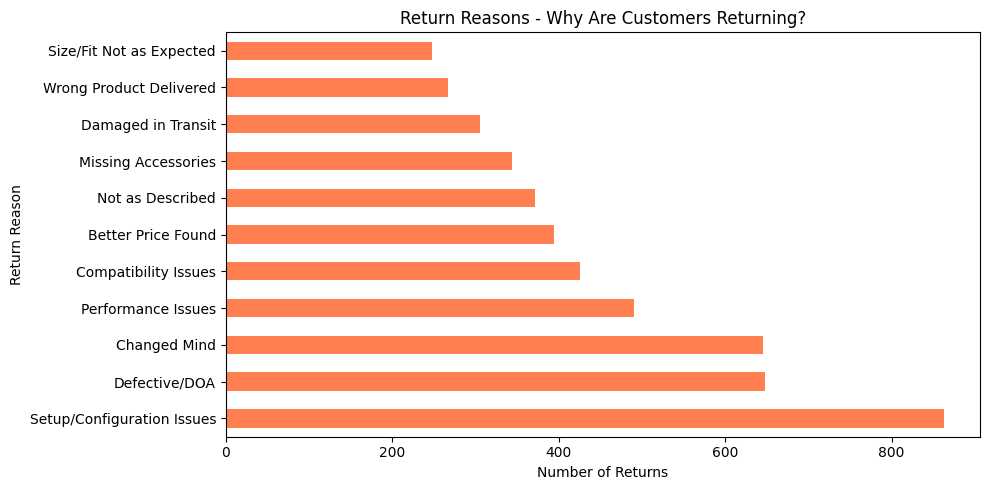

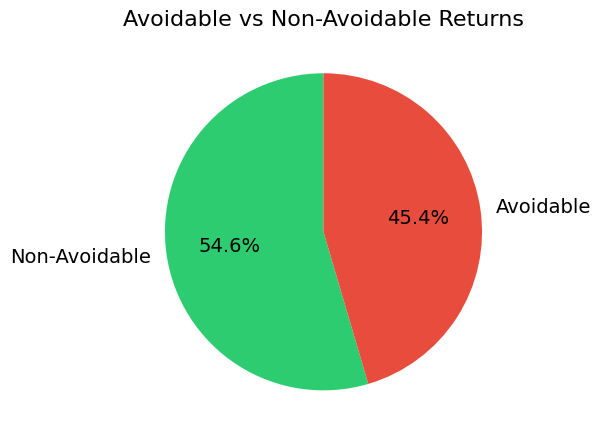


--- Support Channel Effectiveness ---
                    Total_Cases  Returns_Prevented  Avg_CSAT  \
Support_Channel                                                
Live Chat                   687                139      3.14   
Phone Call                  593                 96      3.12   
Step-by-Step Guide          225                 29      3.03   
Self-Service Video          438                 48      2.96   
Brand Website               340                 16      2.87   

                    Prevention_Rate_%  
Support_Channel                        
Live Chat                        20.2  
Phone Call                       16.2  
Step-by-Step Guide               12.9  
Self-Service Video               11.0  
Brand Website                     4.7  

   NOTEBOOK 01 COMPLETE


In [ ]:
# NOTEBOOK 01: DATA EXPLORATION

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load Data
df = pd.read_excel('/returns_dataset.xlsx', sheet_name='Returns_Data')
df['Support_Channel'] = df['Support_Channel'].fillna('No Support Contacted')
print(f"✅ Dataset loaded: {df.shape[0]} rows, {df.shape[1]} columns")

# Check Data Info
print("\n--- Data Info ---")
print(df.info())

# Check Missing Values
missing = df.isnull().sum()
print("\n--- Missing Values ---")
print(missing)
print(f"Total missing: {missing.sum()}")

# Basic Statistics
print("\n--- Statistics ---")
print(df.describe().round(2))

# Calculate KPIs
total_returns = len(df)
avoidable = df['Is_Avoidable_Return'].sum()
contacted_support = df['Customer_Contacted_Support'].sum()
prevented = df['Return_Prevented'].sum()
avg_csat = df['CSAT_Score'].mean()
total_revenue_at_risk = df[df['Is_Avoidable_Return'] == 1]['Product_Price_INR'].sum()

print("\n" + "=" * 50)
print("   PLS RETURNS PROJECT - KEY KPIs")
print("=" * 50)
print(f"  Total Returns:          {total_returns}")
print(f"  Avoidable Returns:      {avoidable} ({avoidable/total_returns*100:.1f}%)")
print(f"  Support Contact Rate:   {contacted_support/total_returns*100:.1f}%")
print(f"  Returns Prevented:      {prevented} ({prevented/total_returns*100:.1f}%)")
print(f"  Avg CSAT Score:         {avg_csat:.2f} / 5")
print(f"  Revenue at Risk:        Rs.{total_revenue_at_risk:,.0f}")
print("=" * 50)

# Chart 1 - Returns by Category
plt.figure(figsize=(10, 5))
df['Product_Category'].value_counts().plot(kind='barh', color='steelblue')
plt.title('Number of Returns by Product Category')
plt.xlabel('Number of Returns')
plt.ylabel('Product Category')
plt.tight_layout()
plt.show()

# Chart 2 - Return Reasons
plt.figure(figsize=(10, 5))
df['Return_Reason'].value_counts().plot(kind='barh', color='coral')
plt.title('Return Reasons - Why Are Customers Returning?')
plt.xlabel('Number of Returns')
plt.ylabel('Return Reason')
plt.tight_layout()
plt.show()

# Chart 3 - Avoidable vs Non-Avoidable
plt.figure(figsize=(6, 6))
sizes = [len(df[df['Is_Avoidable_Return']==0]), len(df[df['Is_Avoidable_Return']==1])]
plt.pie(sizes, labels=['Non-Avoidable','Avoidable'], autopct='%1.1f%%',
        colors=['#2ecc71','#e74c3c'], startangle=90, textprops={'fontsize': 14})
plt.title('Avoidable vs Non-Avoidable Returns', fontsize=16)
plt.tight_layout()
plt.show()

# Support Channel Analysis
support_df = df[df['Support_Channel'] != 'No Support Contacted']
channel_stats = support_df.groupby('Support_Channel').agg(
    Total_Cases=('Order_ID', 'count'),
    Returns_Prevented=('Return_Prevented', 'sum'),
    Avg_CSAT=('CSAT_Score', 'mean')
).round(2)
channel_stats['Prevention_Rate_%'] = (channel_stats['Returns_Prevented'] / channel_stats['Total_Cases'] * 100).round(1)
print("\n--- Support Channel Effectiveness ---")
print(channel_stats.sort_values('Prevention_Rate_%', ascending=False))

print("\n" + "=" * 55)
print("   NOTEBOOK 01 COMPLETE")
print("=" * 55)